# Chapter 6: k Nearest Neighbours

In [78]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
from sklearn.datasets import make_blobs
from sklearn.neighbors import KNeighborsClassifier
from sklearn import metrics
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score


from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

## 6.1 Introduction & Motivation

As last classical classifier, we'll check ot the k-NN (Nearest Neighbors) algorithm. This is based on the very simple and logical idea that observations of the same class must resemble each other. In our digit examples this definitely makes sense, but what does this concetely mean and how can we tell a computer when things resemble each other?

This and much more is what we'll learn in this chapter! Excited yet?

## 6.2 Problem Setting

Once again, no surprises should be found in the following setup:

Image Data Shape (1797, 64)
Label Data Shape (1797,)


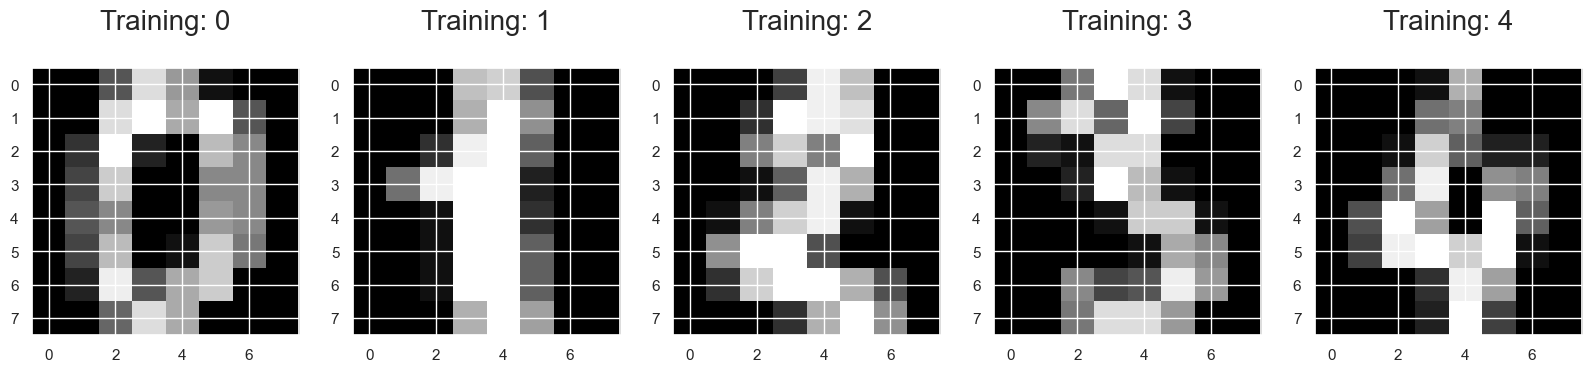

In [79]:
digits = datasets.load_digits()
dir(digits)
# data
# Print to show there are 1797 images (8 by 8 images for a dimensionality of 64)
print("Image Data Shape" , digits.data.shape)
# Print to show there are 1797 labels (integers from 0–9)
print("Label Data Shape", digits.target.shape)
plt.figure(figsize=(20,4))
for index, (image, label) in enumerate(zip(digits.data[0:5], digits.target[0:5])):
 plt.subplot(1, 5, index + 1)
 plt.imshow(np.reshape(image, (8,8)), cmap=plt.cm.gray)
 plt.title('Training: %i\n' % label, fontsize = 20)
X_train, X_test, y_train, y_test = train_test_split(digits.data, digits.target, test_size=0.25, random_state=0)

## 6.3 Model

### 6.3.1 Model

In our digit database the indepent variables are difficult to illustrate, so let's look at a dataset like we did in the previous chapter:

![alt text](https://depiesml.files.wordpress.com/2015/08/knn_plot.png?w=600&h=586)

If we want a model to classify this type of data, we'll make use of one very important property of classes of data: they flock together in the right dimensions. That is, in these two variables (F1 and F2), we can clearly see that all the points of the same class are bunled together. In average, we can say that if we take a random blue point, we'll easier find another blue point nearby rather than say a green or red one.

It is exactly this what kNN does: it takes a point which we want to predict. For example, the grey point:

![alt text](https://depiesml.files.wordpress.com/2015/08/knn-k5-initial1.png?w=600&h=586)

The kNN algorithm then calculates the distance of all points starting from that point, and selects the $k$ nearest datapoints. 

![](https://depiesml.files.wordpress.com/2015/08/knn-k5-neighbor.png)

These points then "vote" on which class we would like to predict. Different voting schemes are possible; but most straightforward will be that: the class which is represented the most will be the prediction.

### 6.3.2 Model Estimation

That all sounds easy enough, but let's put that into practice.
We'll make a 9-Nearest-Neighbours classifier and fit it onto our data:

In [80]:
# Basismodel met k = 9
neigh = KNeighborsClassifier(n_neighbors=9)
neigh.fit(X_train, y_train)
predictions = neigh.predict(X_test)
accuracy = accuracy_score(y_test, predictions)
print(f'Accuracy for k=9: {accuracy}')

Accuracy for k=9: 0.9777777777777777


Best k based on accuracy: 1 with accuracy = 0.9911
Best k based on macro precision: 1 with precision = 0.9915


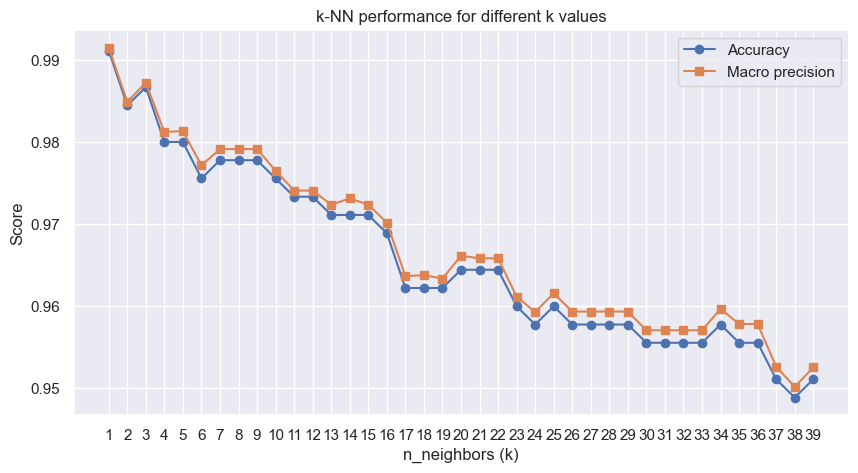

In [81]:
k_values = range(1, 40)
accuracies = []
precisions = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    accuracies.append(accuracy_score(y_test, preds))
    precisions.append(precision_score(y_test, preds, average='macro', zero_division=0))

optimal_k_accuracy = k_values[int(np.argmax(accuracies))]
optimal_k_precision = k_values[int(np.argmax(precisions))]

print(f'Best k based on accuracy: {optimal_k_accuracy} with accuracy = {max(accuracies):.4f}')
print(f'Best k based on macro precision: {optimal_k_precision} with precision = {max(precisions):.4f}')

plt.figure(figsize=(10, 5))
plt.plot(list(k_values), accuracies, marker='o', label='Accuracy')
plt.plot(list(k_values), precisions, marker='s', label='Macro precision')
plt.xlabel('n_neighbors (k)')
plt.ylabel('Score')
plt.title('k-NN performance for different k values')
plt.xticks(list(k_values))
plt.legend()
plt.show()

# Gebruik het beste model verder in de notebook
best_k = optimal_k_accuracy
best_model = KNeighborsClassifier(n_neighbors=best_k)
best_model.fit(X_train, y_train)
predictions = best_model.predict(X_test)

Next we can either make a prediction for a certain observation, multiple observations, or all observations of our test set:

In [82]:
# Predict for one observation
print('Prediction for first test image:', best_model.predict(X_test[0].reshape(1, -1))[0])
print('True label:', y_test[0])

# Predict for ten observations
print('Predictions for first 10 test images:', best_model.predict(X_test[0:10]))

# Predict for all observations of the test set
predictions = best_model.predict(X_test)

Prediction for first test image: 2
True label: 2
Predictions for first 10 test images: [2 8 2 6 6 7 1 9 8 5]


## 6.4 Model Evaluation

### Accuracy

In [83]:
# Accuracy of the optimal model
accuracy = accuracy_score(y_test, predictions)
print(f'Accuracy of the optimal model (k={best_k}): {accuracy}')

Accuracy of the optimal model (k=1): 0.9911111111111112


##### Question 1: Tweak the n_neighbors parameter to check which model gives the highest accuracy. Interpret! Explain what is happening in the model, and what the influence is on the accuracy. Is this logical? Are there any restraints on this parameter?


**Answer:** In this split of the digits dataset, the highest accuracy is obtained at **k = 1** (about **0.9911**). With a very small value of `k`, the model looks only at the closest neighbours, so it can capture local patterns very well. If `k` becomes larger, the model smooths too much and starts averaging over more neighbours, which can slightly reduce performance. That is logical: a low `k` is flexible, while a high `k` is more conservative and may underfit.

There are restraints on this parameter: `k` must be at least **1** and cannot be larger than the number of training observations. In practice, an **odd** value is often chosen to reduce ties in classification.

### Precision

In [84]:
print(f'Macro precision of the optimal model (k={best_k}): {precision_score(y_test, predictions, average='macro', zero_division=0):.4f}')
print(classification_report(y_test, predictions))

Macro precision of the optimal model (k=1): 0.9915
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        37
           1       1.00      1.00      1.00        43
           2       1.00      0.98      0.99        44
           3       0.96      1.00      0.98        45
           4       1.00      1.00      1.00        38
           5       0.98      0.98      0.98        48
           6       1.00      1.00      1.00        52
           7       1.00      1.00      1.00        48
           8       1.00      1.00      1.00        48
           9       0.98      0.96      0.97        47

    accuracy                           0.99       450
   macro avg       0.99      0.99      0.99       450
weighted avg       0.99      0.99      0.99       450



##### Question 2: Question 1: Tweak the n_neighbors parameter to check which model gives the highest accuracy. Interpret! Explain what is happening in the model, and what the influence is on precision. Is this logical? 

**Answer:** Precision follows the same general pattern as accuracy in this notebook. The best macro precision is also reached at **k = 1** (about **0.9915**). This means that when the model predicts a class, it is almost always correct. As `k` grows, the classifier becomes less sensitive to local detail. That makes the predictions a bit more averaged out, and some classes start getting confused more often, so precision drops slightly. This is logical for k-NN: a large neighbourhood can blur class boundaries.

### Confusion Matrix

You should by now be familiar with the confusion Matrix. 

##### Question 3: Make the confusion matrix and interpret it.

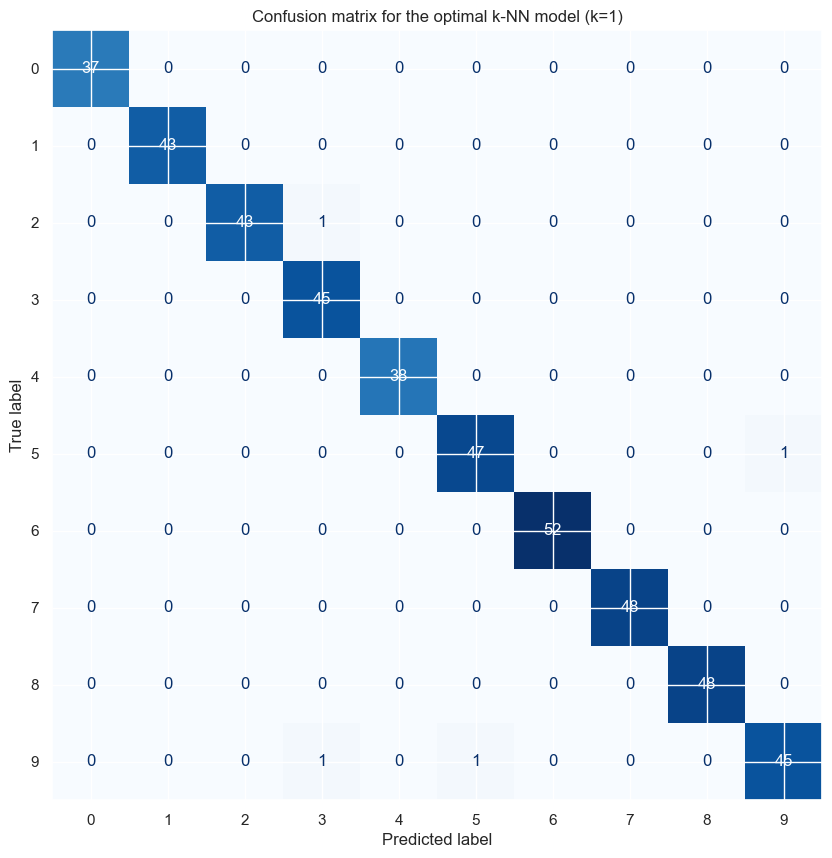

In [85]:
cm = confusion_matrix(y_test, predictions)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=digits.target_names)
fig, ax = plt.subplots(figsize=(10, 10))
disp.plot(ax=ax, cmap='Blues', colorbar=False)
plt.title(f'Confusion matrix for the optimal k-NN model (k={best_k})')
plt.show()

**Interpretation:** The confusion matrix is almost perfectly diagonal, which means most digits are classified correctly. The few mistakes are limited to visually similar digits, for example a small confusion between **2 and 3**, and between **9 and 3/5**. So the model performs very strongly overall, with only a handful of errors.

## 6.5 Exercises

In [86]:
comparison_models = {
    f'k-NN (k={best_k})': KNeighborsClassifier(n_neighbors=best_k),
    'Logistic Regression': LogisticRegression(max_iter=5000),
    'Decision Tree': DecisionTreeClassifier(random_state=0),
}

for name, model in comparison_models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, average='macro', zero_division=0)
    print(f'{name}: accuracy = {acc}, macro precision = {prec}')

k-NN (k=1): accuracy = 0.9911111111111112, macro precision = 0.9914874344742521
Logistic Regression: accuracy = 0.9533333333333334, macro precision = 0.9546199638360893
Decision Tree: accuracy = 0.8377777777777777, macro precision = 0.8423997576363345


##### Question 1: See section 6.4
##### Question 2: See section 6.4
##### Question 3: See section 6.4
##### Question 4: Compare the optimal n_neighbours model to the optimal logistic regression and decision tree. Which model do you prefer based upon the accuracy? Which model do you prefer based upon the precision? Which model overall? Or is there no unambiguous choice to be made?

**Answer:** On this same train/test split, the comparison is:
- **Optimal k-NN (k=1):** accuracy = **0.9911**, macro precision = **0.9915**
- **Logistic regression:** accuracy = **0.9533**, macro precision = **0.9546**
- **Decision tree:** accuracy = **0.8378**, macro precision = **0.8424**

Based on both **accuracy** and **precision**, I would prefer **k-NN** for this dataset. Logistic regression is still a strong and simpler baseline, but it performs worse here. The decision tree is the weakest of the three on this task. So in this case there **is** a fairly unambiguous choice: **k-NN** is the best overall model among these three.